In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection

from sir_graph.dynamics import run_ensemble, simulate
from sir_graph.geometric import expected_mean_degree, random_geometric
from sir_graph.parameters import NodeParams
from sir_graph.states import State, choose_seeds

from ipywidgets import IntSlider, interact


N_NODES, RADIUS = 250, 0.15
P, Q = 0.7, 1.0
N_SEEDS = 2
rng = np.random.default_rng(22)

edges: 1947
mean degree: 15.58 (theory 15.42)


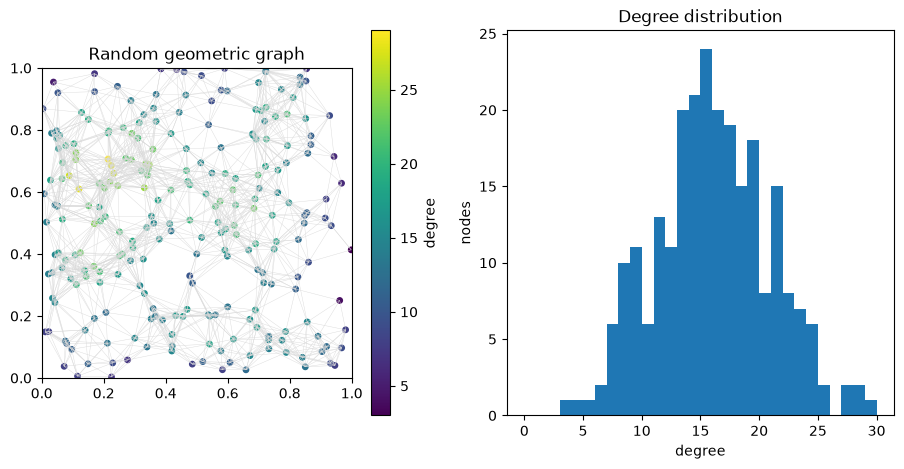

In [2]:
graph, pos = random_geometric(N_NODES, RADIUS, rng=rng)
degrees = np.diff(graph.indptr)

print(f"edges: {graph.n_edges}")
print(f"mean degree: {degrees.mean():.2f} (theory {expected_mean_degree(N_NODES, RADIUS):.2f})")

def draw_edges(ax, graph, pos):
    src = np.repeat(np.arange(graph.n_nodes), np.diff(graph.indptr))
    keep = src < graph.indices
    segs = np.stack([pos[src[keep]], pos[graph.indices[keep]]], axis=1)
    ax.add_collection(LineCollection(segs, colors="0.85", linewidths=0.3))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5))
draw_edges(ax1, graph, pos)
sc = ax1.scatter(*pos.T, c=degrees, s=15, cmap="viridis")
fig.colorbar(sc, ax=ax1, label="degree")
ax1.set(aspect="equal", xlim=(0, 1), ylim=(0, 1), title="Random geometric graph")
ax2.hist(degrees, bins=range(degrees.max() + 2))
ax2.set(xlabel="degree", ylabel="nodes", title="Degree distribution")
plt.show()

final size: 250/250 after 7 steps


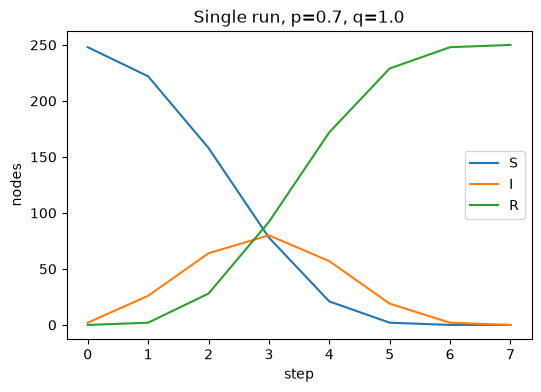

In [3]:
params = NodeParams.homogeneous(N_NODES, recovery=Q)
seeds = choose_seeds(N_NODES, N_SEEDS, rng=rng)
result = simulate(graph, seeds, P, params, rng=rng)

print(f"final size: {result.final_size}/{N_NODES} after {result.n_steps} steps")

fig, ax = plt.subplots(figsize=(6, 4))
for s in State:
    ax.plot(result.counts[:, s], label=s.name)
ax.set(xlabel="step", ylabel="nodes", title=f"Single run, p={P}, q={Q}")
ax.legend()
plt.show()

In [4]:
def state_at(result, t):
    """Reconstruct the S/I/R state of every node at time t."""
    inf_t, rec_t = result.infection_time, result.recovery_time
    state = np.full(result.n_nodes, State.S, dtype=np.int8)
    infected = (inf_t >= 0) & (inf_t <= t)
    state[infected] = State.I
    state[(rec_t >= 0) & (rec_t <= t)] = State.R
    return state

In [5]:

COLORS = np.array(["tab:blue", "tab:red", "tab:green"])   # S, I, R

def plot_at(t):
    state = state_at(result, t)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

    draw_edges(ax1, graph, pos)
    ax1.scatter(*pos.T, c=COLORS[state], s=10)
    ax1.scatter(*pos[result.seeds].T, marker=".", c="orange", s=120)
    ax1.set(aspect="equal", xlim=(0, 1), ylim=(0, 1), title=f"t = {t}")

    for s in State:
        ax2.plot(result.counts[:, s], color=COLORS[s], label=s.name)
    ax2.axvline(t, color="black", linestyle="--")
    ax2.set(xlabel="step", ylabel="nodes")
    ax2.legend()
    plt.show()

interact(plot_at, t=IntSlider(min=0, max=result.n_steps, step=1, value=0));

interactive(children=(IntSlider(value=0, description='t', max=7), Output()), _dom_classes=('widget-interact',)…

In [7]:
from sir_graph.attributes import NodeAttributes

attributes = NodeAttributes.random(
    N_NODES,
    rng=22,
)

In [8]:
i = 0

print("Node:", i)
print("Age group:", attributes.age_group[i])
print("Sex:", attributes.sex[i])
print("Occupation:", attributes.occupation[i])
print("Household size:", attributes.household_size[i])
print("Mobility:", attributes.mobility[i])
print("Vaccinated:", attributes.vaccinated[i])

Node: 0
Age group: young_adult
Sex: male
Occupation: office
Household size: 6
Mobility: low
Vaccinated: False
